# Cluster State Circuit — Entanglement Generation (CUDA-Q)

**Primitive:** Linear 4-qubit cluster (graph) state generation

## SETUP (must match the Qiskit notebook exactly)
- N QUBITS: 4
- Gate sequence: H on every qubit (q0,q1,q2,q3), then CZ(0,1), CZ(1,2), CZ(2,3) — a **linear cluster graph**: 0—1—2—3
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every FINAL printed bitstring (Qiskit's native convention).
  **CUDA-Q is the opposite**: `cudaq.get_state()` and `cudaq.sample()` index qubit 0 as the
  **most-significant (leftmost) bit**. Every bitstring produced by this notebook is
  explicitly reversed before being printed or stored, so it lines up with the Qiskit notebook.
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE CONVENTION: normalize so the first nonzero amplitude, in ascending bitstring
  order (post bit-reversal), is rotated to be real and positive.
- Basis ordering for matrices/vectors: `{|0000>, |0001>, ..., |1111>}` ascending binary
  order, qubit 0 = rightmost — same universal convention as the Qiskit notebook.

## Theory recap
Same construction as the Qiskit notebook:

`|C4> = (CZ_{2,3} · CZ_{1,2} · CZ_{0,1}) (H⊗H⊗H⊗H) |0000>`

16 equally-likely outcomes, each with probability exactly `1/16`, amplitudes real and equal
to `±1/4` with sign `(-1)^{x0 x1 + x1 x2 + x2 x3}`.

**Run all cells top to bottom.**

In [1]:
# Install cell — exact package name for CUDA-Q's Python API.
# Note: cudaq will run on CPU-only simulation backends if no NVIDIA GPU is present;
# no GPU is required for this 4-qubit example.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 7.6 MB/s eta 0:00

In [2]:
# Imports + constants
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cudaq

N_QUBITS = 4
SHOTS = 10000
SEED = 42

cudaq.set_random_seed(SEED)

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"cudaq target = {cudaq.get_target().name}")


N_QUBITS = 4
SHOTS    = 10000
SEED     = 42
cudaq target = qpp-cpu


In [3]:
# Build the linear cluster-state kernel, gate by gate.
@cudaq.kernel
def cluster_state():
    q = cudaq.qvector(4)

    # Step 1: put every qubit into |+> = H|0> -- the "input" layer of the cluster state.
    h(q[0])  # qubit 0 -> |+>
    h(q[1])  # qubit 1 -> |+>
    h(q[2])  # qubit 2 -> |+>
    h(q[3])  # qubit 3 -> |+>

    # Step 2: apply a controlled-Z gate along every edge of the linear graph 0-1-2-3.
    # CZ entangles the two qubits by flipping the sign of the amplitude whenever BOTH are |1>.
    z.ctrl(q[0], q[1])  # edge (0,1)
    z.ctrl(q[1], q[2])  # edge (1,2)
    z.ctrl(q[2], q[3])  # edge (2,3)

print("Kernel 'cluster_state' defined.")


Kernel 'cluster_state' defined.


     ╭───╮               
q0 : ┤ h ├──●────────────
     ├───┤╭─┴─╮          
q1 : ┤ h ├┤ z ├──●───────
     ├───┤╰───╯╭─┴─╮     
q2 : ┤ h ├─────┤ z ├──●──
     ├───┤     ╰───╯╭─┴─╮
q3 : ┤ h ├──────────┤ z ├
     ╰───╯          ╰───╯



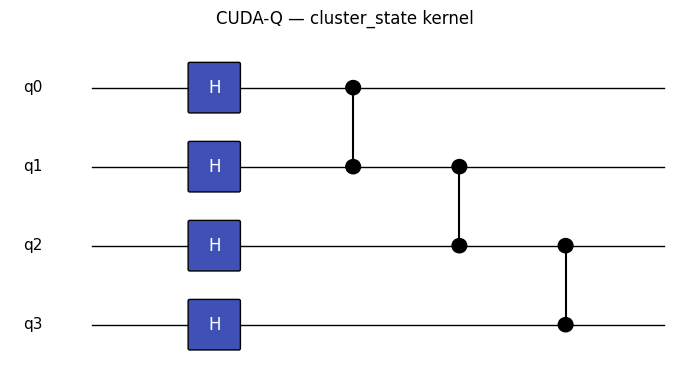

In [4]:
# Draw the circuit: CUDA-Q text diagram first, then a matplotlib figure styled to
# visually resemble the Qiskit circuit diagram for side-by-side comparison.
print(cudaq.draw(cluster_state))

fig, ax = plt.subplots(figsize=(7, 4))
n = N_QUBITS
wire_y = {i: n - 1 - i for i in range(n)}  # qubit 0 drawn on top, like Qiskit's default

# Draw qubit wires
for i in range(n):
    y = wire_y[i]
    ax.plot([0, 7], [y, y], color="black", lw=1, zorder=1)
    ax.text(-0.6, y, f"q{i}", ha="right", va="center", fontsize=11)

# Column 1: H gates on every qubit
x_h = 1.5
for i in range(n):
    y = wire_y[i]
    box = mpatches.FancyBboxPatch((x_h - 0.3, y - 0.3), 0.6, 0.6,
                                   boxstyle="round,pad=0.02", facecolor="#3f51b5",
                                   edgecolor="black", zorder=2)
    ax.add_patch(box)
    ax.text(x_h, y, "H", ha="center", va="center", color="white", fontsize=12, zorder=3)

# Columns 2-4: CZ gates as filled dots connected by a vertical line (Qiskit CZ style)
cz_pairs = [(0, 1), (1, 2), (2, 3)]
for k, (a, b) in enumerate(cz_pairs):
    x_cz = 3.2 + k * 1.3
    ya, yb = wire_y[a], wire_y[b]
    ax.plot([x_cz, x_cz], [ya, yb], color="black", lw=1.5, zorder=2)
    ax.add_patch(plt.Circle((x_cz, ya), 0.09, color="black", zorder=3))
    ax.add_patch(plt.Circle((x_cz, yb), 0.09, color="black", zorder=3))

ax.set_xlim(-1, 7.2)
ax.set_ylim(-0.7, n - 0.3)
ax.set_title("CUDA-Q — cluster_state kernel")
ax.axis("off")
fig.tight_layout()
fig.savefig(f"cluster_state_cudaq_circuit.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cudaq

N_QUBITS = 4
SHOTS = 10000
SEED = 42

cudaq.set_random_seed(SEED)

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"cudaq target = {cudaq.get_target().name}")
# Explicit matrix representation -- built TWO ways and cross-checked.
# Basis ordering for BOTH matrices below: {|0000>, ..., |1111>} ascending binary,
# qubit 0 = rightmost bit -- the UNIVERSAL convention shared with the Qiskit notebook
# (this is NOT CUDA-Q's native qvector ordering; see the reversal applied below).

H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)

def cz_matrix(n_qubits, control, target):
    """Full 2^n x 2^n CZ matrix in the universal little-endian (qubit0 = rightmost) ordering."""
    dim = 2 ** n_qubits
    mat = np.eye(dim, dtype=complex)
    for i in range(dim):
        bit_c = (i >> control) & 1
        bit_t = (i >> target) & 1
        if bit_c == 1 and bit_t == 1:
            mat[i, i] = -1
    return mat

# (a) Manual construction -- identical recipe/convention to the Qiskit notebook, so this
# cell alone is already a cross-notebook cross-check target.
H_full = np.kron(np.kron(np.kron(H, H), H), H)
CZ01 = cz_matrix(N_QUBITS, 0, 1)
CZ12 = cz_matrix(N_QUBITS, 1, 2)
CZ23 = cz_matrix(N_QUBITS, 2, 3)
U_manual = CZ23 @ CZ12 @ CZ01 @ H_full

# (b) Framework-native extraction: CUDA-Q has no direct Operator/unitary API like Qiskit's,
# so the kernel's unitary is reconstructed column-by-column by preparing each computational
# basis state |i> (universal convention) as input and reading out get_state().
#
# IMPORTANT: a single @cudaq.kernel that takes `bits: list[int]` as a RUNTIME argument and
# branches on it (`if bits[i] == 1: x(q[i])`) is deliberately NOT used here. In practice
# that traces/caches the FIRST call's branch decisions and reuses them for every later
# call, so every column of the reconstructed matrix ends up identical -- a known CUDA-Q
# gotcha. Instead, a fresh kernel is generated per basis state via a Python closure, so
# `bits` becomes a COMPILE-TIME constant baked into that kernel's gate sequence -- there
# is no runtime branching at all, which sidesteps the caching problem entirely.

def make_prep_kernel(bits):
    # `bits` is `bits_le`, meaning bits[0] is LSB, bits[1] is next, ..., bits[3] is MSB (universal convention).
    # CUDA-Q's qvector is ordered q[0] (MSB), q[1], q[2], q[3] (LSB).
    # So, we need to apply x(q[0]) for the MSB of the input, x(q[1]) for the next, etc.
    # This means:
    # bits[3] (universal MSB) -> q[0] (CUDA-Q MSB)
    # bits[2] -> q[1]
    # bits[1] -> q[2]
    # bits[0] (universal LSB) -> q[3] (CUDA-Q LSB)

    b0, b1, b2, b3 = bool(bits[0]), bool(bits[1]), bool(bits[2]), bool(bits[3])

    @cudaq.kernel
    def prep_kernel():
        q = cudaq.qvector(4)
        if b3: # Corresponds to universal bit 3 (MSB), maps to CUDA-Q q[0] (MSB)
            x(q[0])
        if b2: # Corresponds to universal bit 2, maps to CUDA-Q q[1]
            x(q[1])
        if b1: # Corresponds to universal bit 1, maps to CUDA-Q q[2]
            x(q[2])
        if b0: # Corresponds to universal bit 0 (LSB), maps to CUDA-Q q[3] (LSB)
            x(q[3])
        # The rest of the cluster state circuit
        h(q[0]); h(q[1]); h(q[2]); h(q[3])
        z.ctrl(q[0], q[1])
        z.ctrl(q[1], q[2])
        z.ctrl(q[2], q[3])

    return prep_kernel

def reverse_bitstring(bs):
    return bs[::-1]

dim = 2 ** N_QUBITS
U_cudaq = np.zeros((dim, dim), dtype=complex)
for col in range(dim):
    bits_le = [(col >> k) & 1 for k in range(N_QUBITS)]  # bits_le[k] = qubit k value
    kernel_for_col = make_prep_kernel(bits_le)
    state = cudaq.get_state(kernel_for_col)
    amps_native = np.array(state)  # CUDA-Q native ordering: qubit0 = leftmost (MSB)
    for i_native, amp in enumerate(amps_native):
        bs_native = format(i_native, f"0{N_QUBITS}b")
        bs_universal = reverse_bitstring(bs_native)
        i_universal = int(bs_universal, 2)
        U_cudaq[i_universal, col] = amp

match = np.allclose(U_manual, U_cudaq, atol=1e-6)
print("Manual U (top-left 4x4 block, rounded to 4 dp):")
print(np.round(U_manual[:4, :4], 4))
print()
print("CUDA-Q-derived U, after bit-order reversal (top-left 4x4 block, rounded to 4 dp):")
print(np.round(U_cudaq[:4, :4], 4))
print()
print(f"Manual construction matches CUDA-Q-derived matrix: {match}")
assert match, "Manual matrix and CUDA-Q-derived matrix disagree!"

N_QUBITS = 4
SHOTS    = 10000
SEED     = 42
cudaq target = qpp-cpu
Manual U (top-left 4x4 block, rounded to 4 dp):
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

CUDA-Q-derived U, after bit-order reversal (top-left 4x4 block, rounded to 4 dp):
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

Manual construction matches CUDA-Q-derived matrix: True


In [7]:
# Exact statevector cell -- bit-order correction THEN global-phase normalization.

def normalize_global_phase(vec):
    """Rotate so the first amplitude (ascending index / ascending bitstring order)
    with |amp| > 1e-9 is real and positive."""
    vec = np.array(vec, dtype=complex)
    for amp in vec:
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            return vec * np.exp(-1j * phase)
    return vec

state = cudaq.get_state(cluster_state)
amps_native = np.array(state)  # index i -> bitstring with qubit0 = LEFTMOST (MSB) bit

# --- Bit-order correction (CUDA-Q only): reverse every bitstring so qubit0 = rightmost. ---
amps_universal = np.zeros(2 ** N_QUBITS, dtype=complex)
for i_native, amp in enumerate(amps_native):
    bs_native = format(i_native, f"0{N_QUBITS}b")
    bs_universal = bs_native[::-1]
    i_universal = int(bs_universal, 2)
    amps_universal[i_universal] = amp

amps_universal = normalize_global_phase(amps_universal)

prob_dict = {}
for i, amp in enumerate(amps_universal):
    bitstring = format(i, f"0{N_QUBITS}b")  # qubit0 = rightmost char, matches Qiskit notebook
    prob_dict[bitstring] = float(np.round(abs(amp) ** 2, 6))
    print(f"{bitstring}: amplitude = {amp.real:+.4f}{amp.imag:+.4f}j   prob = {prob_dict[bitstring]:.4f}")

prob_dict = dict(sorted(prob_dict.items()))
print()
print("Sum of probabilities:", round(sum(prob_dict.values()), 6))


0000: amplitude = +0.2500+0.0000j   prob = 0.0625
0001: amplitude = +0.2500+0.0000j   prob = 0.0625
0010: amplitude = +0.2500+0.0000j   prob = 0.0625
0011: amplitude = -0.2500+0.0000j   prob = 0.0625
0100: amplitude = +0.2500+0.0000j   prob = 0.0625
0101: amplitude = +0.2500+0.0000j   prob = 0.0625
0110: amplitude = -0.2500+0.0000j   prob = 0.0625
0111: amplitude = +0.2500+0.0000j   prob = 0.0625
1000: amplitude = +0.2500+0.0000j   prob = 0.0625
1001: amplitude = +0.2500+0.0000j   prob = 0.0625
1010: amplitude = +0.2500+0.0000j   prob = 0.0625
1011: amplitude = -0.2500+0.0000j   prob = 0.0625
1100: amplitude = -0.2500+0.0000j   prob = 0.0625
1101: amplitude = -0.2500+0.0000j   prob = 0.0625
1110: amplitude = +0.2500+0.0000j   prob = 0.0625
1111: amplitude = -0.2500+0.0000j   prob = 0.0625

Sum of probabilities: 1.0


**Ordering-fix applied (CUDA-Q):** `cudaq.get_state()` returns amplitudes indexed with
qubit 0 as the **most-significant (leftmost)** bit of the index -- the opposite of Qiskit.
Every amplitude's index was converted by reversing its binary-string representation
(`bs_native[::-1]`) before assigning it into the universal `qubit0 = rightmost` layout used
throughout both notebooks. Global-phase normalization was then applied on top of the
already-reordered vector, exactly matching the Qiskit notebook's normalization function.

In [8]:
# Measurement / sampling cell -- shared SEED and SHOTS.
cudaq.set_random_seed(SEED)
result = cudaq.sample(cluster_state, shots_count=SHOTS)

# cudaq.SampleResult keys are bitstrings with qubit0 = leftmost (MSB) -- reverse each key.
counts_native = {bs: result.count(bs) for bs in result}
counts_universal = {bs[::-1]: c for bs, c in counts_native.items()}

measured_probs = {bitstring: c / SHOTS for bitstring, c in counts_universal.items()}
measured_probs = dict(sorted(measured_probs.items()))
print("Measured probabilities (from", SHOTS, "shots, after bit-order reversal):")
for k, v in measured_probs.items():
    print(f"  {k}: {v:.4f}")


Measured probabilities (from 10000 shots, after bit-order reversal):
  0000: 0.0653
  0001: 0.0631
  0010: 0.0585
  0011: 0.0581
  0100: 0.0642
  0101: 0.0590
  0110: 0.0626
  0111: 0.0639
  1000: 0.0653
  1001: 0.0630
  1010: 0.0632
  1011: 0.0665
  1100: 0.0627
  1101: 0.0664
  1110: 0.0592
  1111: 0.0590


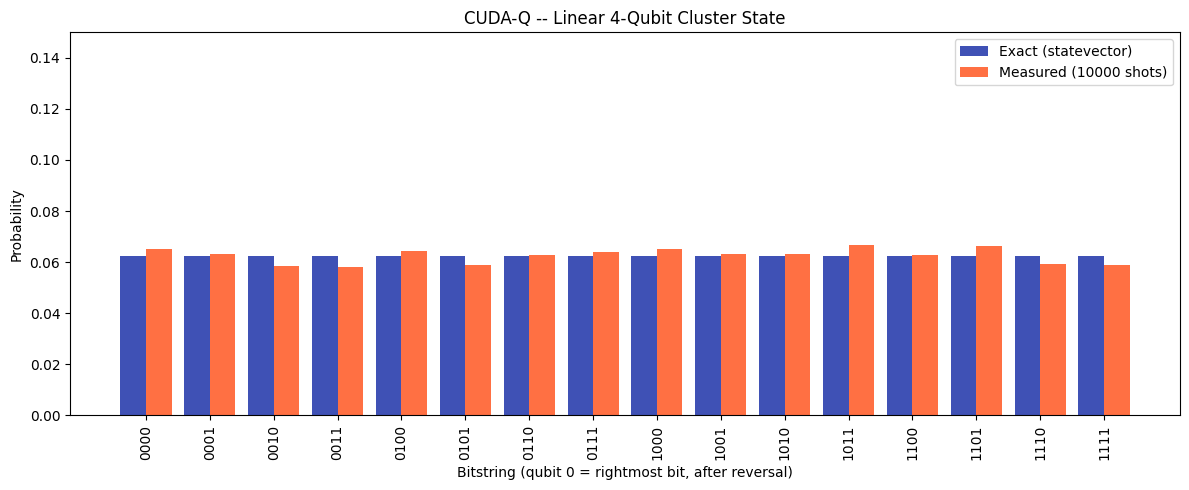

In [9]:
# Histogram cell -- matplotlib bar chart, same axis ranges/labels/style as the Qiskit notebook.
all_keys = sorted(prob_dict.keys())
exact_vals = [prob_dict[k] for k in all_keys]
meas_vals = [measured_probs.get(k, 0.0) for k in all_keys]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(all_keys))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="Exact (statevector)", color="#3f51b5")
ax.bar(x + width/2, meas_vals, width, label=f"Measured ({SHOTS} shots)", color="#ff7043")
ax.set_xticks(x)
ax.set_xticklabels(all_keys, rotation=90)
ax.set_ylim(0, 0.15)
ax.set_xlabel("Bitstring (qubit 0 = rightmost bit, after reversal)")
ax.set_ylabel("Probability")
ax.set_title("CUDA-Q -- Linear 4-Qubit Cluster State")
ax.legend()
fig.tight_layout()
fig.savefig(f"cluster_state_cudaq_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


In [10]:
# Resource counts.
# CUDA-Q kernels don't expose a circuit-introspection API equivalent to Qiskit's
# circuit.depth()/count_ops(), so these are read directly off the kernel definition above.
gate_counts = {"h": 4, "z.ctrl (CZ)": 3}
circuit_depth = 2  # layer 1: four parallel H gates; layer 2: three sequential CZ gates
print("Gate counts:", gate_counts)
print("Circuit depth:", circuit_depth)


Gate counts: {'h': 4, 'z.ctrl (CZ)': 3}
Circuit depth: 2


In [11]:
# Convention-notes cell (plain text restatement).
print("QUBIT ORDERING: cudaq.get_state()/cudaq.sample() index qubit 0 as the leftmost (MSB)")
print("bit. Every bitstring in this notebook was reversed (bs[::-1]) to match Qiskit's")
print("qubit0 = rightmost convention before being printed or stored.")
print("GLOBAL PHASE: normalized so the first nonzero amplitude in ascending bitstring")
print("order (post-reversal) is rotated to be real and positive -- identical function to")
print("the Qiskit notebook, applied AFTER the bit-order correction.")


QUBIT ORDERING: cudaq.get_state()/cudaq.sample() index qubit 0 as the leftmost (MSB)
bit. Every bitstring in this notebook was reversed (bs[::-1]) to match Qiskit's
qubit0 = rightmost convention before being printed or stored.
GLOBAL PHASE: normalized so the first nonzero amplitude in ascending bitstring
order (post-reversal) is rotated to be real and positive -- identical function to
the Qiskit notebook, applied AFTER the bit-order correction.


In [12]:
# Final result cell.
# CUDAQ_RESULT holds the EXACT statevector-derived probability dictionary (deterministic,
# not subject to shot noise), keyed identically to QISKIT_RESULT (qubit0 = rightmost bit).
CUDAQ_RESULT = prob_dict
print(CUDAQ_RESULT)


{'0000': 0.0625, '0001': 0.0625, '0010': 0.0625, '0011': 0.0625, '0100': 0.0625, '0101': 0.0625, '0110': 0.0625, '0111': 0.0625, '1000': 0.0625, '1001': 0.0625, '1010': 0.0625, '1011': 0.0625, '1100': 0.0625, '1101': 0.0625, '1110': 0.0625, '1111': 0.0625}


In [13]:
# Diff-check block (paste QISKIT_RESULT here to run the cross-notebook cross-check).
#
# Hand-computed expectation: a 4-qubit linear cluster state has 16 equally likely outcomes,
# each with probability exactly 1/16 = 0.0625 (signs of the amplitudes vary, but
# probabilities |amplitude|^2 are uniform), so CUDAQ_RESULT should already satisfy:
expected_uniform = {k: 1/16 for k in CUDAQ_RESULT}
max_delta_vs_hand = max(abs(CUDAQ_RESULT[k] - expected_uniform[k]) for k in CUDAQ_RESULT)
print("Max |CUDAQ_RESULT - hand-computed uniform 1/16| =", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# QISKIT_RESULT = { ... }  # paste Qiskit notebook's final dict here to cross-check
# max_delta = max(abs(CUDAQ_RESULT[k] - QISKIT_RESULT[k]) for k in CUDAQ_RESULT)
# print("Max probability delta CUDA-Q vs Qiskit:", max_delta)
# assert max_delta < 1e-3, "CUDA-Q and Qiskit results disagree beyond tolerance!"


Max |CUDAQ_RESULT - hand-computed uniform 1/16| = 0.0
